## Site Covariance
Explore model error covariance between sites

In [1]:
# Run settings
site_1 = 'Quemazon'
site_2 = 'Santa Fe'
namelist = 'ghec'
forcing_str = '00000000'
version = '0003'
isAlpine = False

In [2]:
# Load environmental variables if on Alpine, otherwise they should be stored
import os

# Configure environmental variables
if isAlpine:
    os.environ['OUTPUT_PATH'] = r'/projects/ccox1@xsede.org/lm4px_modelling/output' #Alpine
    os.environ['SNOTEL_PATH'] = r'/projects/ccox1@xsede.org/data/snotel/'
    os.environ['FORCING_PATH'] = r'/projects/ccox1@xsede.org/lm4px_modelling/forcing/'

In [3]:
%matplotlib ipympl
import xarray as xr
import matplotlib.pyplot as plt
import pandas as pd
#from model_datasets.forcing import LM4Forcing
from model_datasets.output import LM4ModelOutput 
from buildforcing.datasets import PNNLSnotel

Load datasets

In [4]:
model_1 = LM4ModelOutput(site=site_1, forcing_string=forcing_str, namelist=namelist, version=version, spinup=False)
model_2 = LM4ModelOutput(site=site_2, forcing_string=forcing_str, namelist=namelist, version=version, spinup=False)

In [5]:
daily_vars = model_1.get_variables(diag='land_daily')
monthly_vars = model_1.get_variables(diag='land_month')

In [6]:
snotel_1 = PNNLSnotel(site_1, os.environ['SNOTEL_PATH'])
snotel_2 = PNNLSnotel(site_2, os.environ['SNOTEL_PATH'])
snotel_1.load_data()
snotel_2.load_data()

### Calculate daily error

In [8]:
snotel_2.data.head()

,T_max_C,T_min_C,T_avg_C,precip_mm,swe_mm
Date,,,,,
1996-10-01 00:00:00-06:00,NaN,NaN,NaN,0.0,0.0
1996-10-02 00:00:00-06:00,NaN,NaN,NaN,0.0,0.0
1996-10-03 00:00:00-06:00,NaN,NaN,NaN,0.0,0.0
1996-10-04 00:00:00-06:00,NaN,NaN,NaN,0.0,0.0
1996-10-05 00:00:00-06:00,NaN,NaN,NaN,0.0,0.0


In [9]:
model_snow_1 = model_1.get_data(['snow'],'land_daily')
model_snow_2 = model_2.get_data(['snow'],'land_daily')

# Combine model datasets into one dataframe
combined_data = pd.merge(model_snow_1['snow'], model_snow_2['snow'], how='outer', left_index=True, right_index=True, suffixes=('_1', '_2'))


Since all timezones in the western US don't exceed UTC-9, we can safely remove timezones for merging purposes.

In [12]:
# Combine with snotel data
snotel_swe_1 = snotel_1.data['swe_mm']
snotel_swe_2 = snotel_2.data['swe_mm']

# Remove timezone from index
snotel_swe_1.index = snotel_swe_1.index.tz_localize(None)
snotel_swe_2.index = snotel_swe_2.index.tz_localize(None)

# Shift snotel data by 12 hours to match model output time
snotel_swe_1.index = snotel_swe_1.index + pd.Timedelta(hours=12)
snotel_swe_2.index = snotel_swe_2.index + pd.Timedelta(hours=12)

combined_data = pd.merge(combined_data, snotel_swe_1, how='left', left_index=True, right_index=True)
combined_data = pd.merge(combined_data, snotel_swe_2, how='left', left_index=True, right_index=True, suffixes=('_1', '_2'))

In [13]:
# Calculate the daily error between model and snotel
combined_data['error_1'] = combined_data['snow_1'] - combined_data['swe_mm_1']
combined_data['error_2'] = combined_data['snow_2'] - combined_data['swe_mm_2']

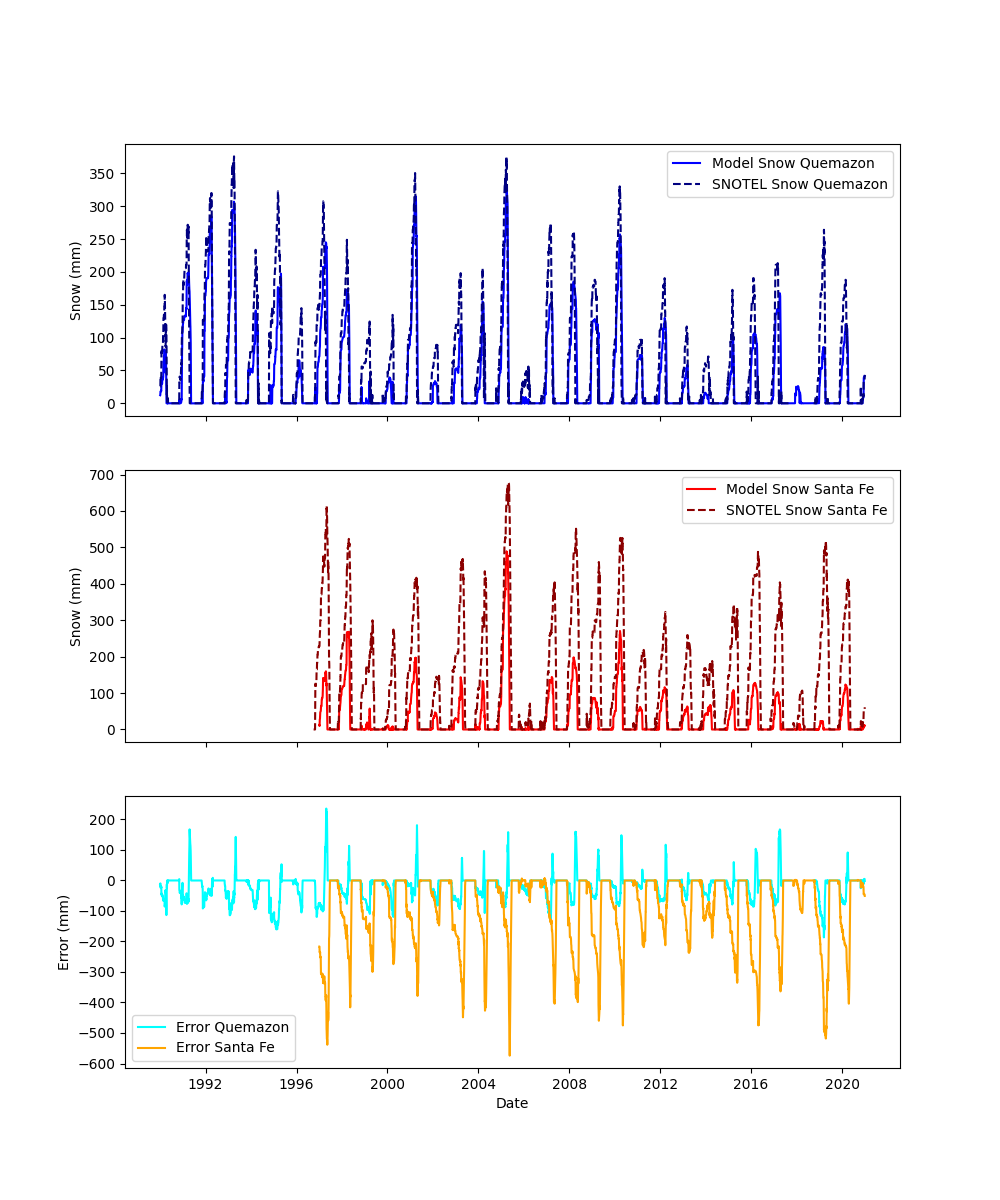

In [16]:
# Plot snow and error in one figure with three subplots
fig, (ax1, ax2, ax3) = plt.subplots(3, 1, figsize=(10, 12), sharex=True)
# First subplot: Model Snow vs SNOTEL Snow for site_1
ax1.plot(combined_data.index, combined_data['snow_1'], label=f'Model Snow {site_1}', color='blue')
ax1.plot(combined_data.index, combined_data['swe_mm_1'], label=f'SNOTEL Snow {site_1}', color='navy', linestyle='--')
ax1.set_ylabel('Snow (mm)')
ax1.legend()

# Second subplot: Model Snow vs SNOTEL Snow for site_2
ax2.plot(combined_data.index, combined_data['snow_2'], label=f'Model Snow {site_2}', color='red')
ax2.plot(combined_data.index, combined_data['swe_mm_2'], label=f'SNOTEL Snow {site_2}', color='darkred', linestyle='--')
ax2.set_ylabel('Snow (mm)')
ax2.legend()

# Third subplot: Error for both sites
ax3.plot(combined_data.index, combined_data['error_1'], label=f'Error {site_1}', color='cyan')
ax3.plot(combined_data.index, combined_data['error_2'], label=f'Error {site_2}', color='orange')
ax3.set_ylabel('Error (mm)')
ax3.set_xlabel('Date')
ax3.legend()

In the case of Quemazon and Santa Fe, the errors are the opposite direction, so the model is overestimating at Quemazon but underestimating at Santa Fe. This is largely the result of lack of downscaling. I am not sure it is worth pursuing this analysis until the error is reduced overall.

#### RMSE Calculation

In [18]:
# Shift snotel data index by 12 hours to match model output timing
snotel_data.index = snotel_data.index + pd.Timedelta(hours=12)

In [19]:
# Combine model and snotel data
combined_df = pd.merge(model_snow, snotel_data[['swe_mm']], left_index=True, right_index=True, how='inner')

In [20]:
# Calculate the difference between model and snotel SWE
combined_df['swe_diff'] = combined_df['snow'] - combined_df['swe_mm']

In [21]:
# Calculate the RMSE
rmse = (combined_df['swe_diff']**2).mean()**0.5
print(f'RMSE between model and SNOTEL SWE: {rmse:.2f} mm')

RMSE between model and SNOTEL SWE: 79.44 mm
